In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [3]:
X = df[["complexity_score", "team_experience_years"]]
y = df["resolution_hours"]

## Feature Selection and Prediction
The target variable (y) is resolution_hours, which represents the time taken to resolve a ticket. The selected input features are complexity_score and team_experience_years because both are assumed to be available when a new ticket needs a resolution-time prediction.

The ticket_id column is excluded because it is an identifier rather than a meaningful predictive feature. Using it could introduce arbitrary patterns that do not generalize to new tickets.

The reopened column is also excluded because its value is determined after the ticket has been resolved and subsequently reopened. Since the goal is to predict resolution time for new, unresolved tickets, this information would not be available at prediction time. Including it would introduce data leakage and would make the model unsuitable for the intended use.

Therefore, the model uses only information available at the time the prediction is made.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
models = {
    "Dummy Regressor (Mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression()
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

df_results = pd.DataFrame(results)

print(df_results.to_string(
    index=False,
    float_format="%.4f"
))

                 Model    MAE    RMSE      R²
Dummy Regressor (Mean) 9.1140 10.5977 -0.0210
     Linear Regression 2.9060  3.5723  0.8840


## Dummy Regressor vs. Linear Regression
- Dummy Regressor: Predicts the average resolution time for every ticket, without considering any input features. Its MAE (9.1140 hours) and RMSE (10.5977 hours) are high, and its negative \(R^2\) score (-0.0210) indicates that it performs slightly worse than simply predicting the mean of the actual test-set values.
- Linear Regression: Uses complexity_score and team_experience_years to predict resolution time. It achieves a much lower MAE (2.9060 hours) and RMSE (3.5723 hours), with an \(R^2\) of 0.8840, meaning it explains approximately 88.4% of the variation in resolution times on the test set.
- Linear Regression substantially outperforms the Dummy Regressor, showing that the selected features provide useful predictive information and that the model makes much more accurate predictions than a simple average-based baseline.

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

polynomial_results = []
polynomial_models = {}

for degree in [2, 3]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    cv_rmse = -cv_scores

    polynomial_results.append({
        "Degree": degree,
        "Mean CV RMSE": cv_rmse.mean(),
        "Std CV RMSE": cv_rmse.std()
    })

    polynomial_models[degree] = model

df_polynomial_cv = pd.DataFrame(polynomial_results)

print(df_polynomial_cv.to_string(
    index=False,
    float_format="%.4f"
))

best_degree = int(
    df_polynomial_cv.loc[
        df_polynomial_cv["Mean CV RMSE"].idxmin(),
        "Degree"
    ]
)

print(f"\nSelected degree: {best_degree}")


 Degree  Mean CV RMSE  Std CV RMSE
      2        3.8325       0.4614
      3        3.8766       0.3144

Selected degree: 2


## Polynomial Regression: Degree 2 vs. Degree 3
- Degree 2: Achieved a mean cross-validation RMSE of 3.8325 hours and a standard deviation of 0.4614 hours. Its lower RMSE indicates slightly better average predictive performance across the five cross-validation folds.
- Degree 3: Achieved a mean cross-validation RMSE of 3.8766 hours and a standard deviation of 0.3144 hours. Although its average error is slightly higher, its lower standard deviation suggests more consistent performance across the folds.

In [7]:
linear_model = LinearRegression()

polynomial_model = make_pipeline(
    PolynomialFeatures(degree=best_degree, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(X_train, y_train)
polynomial_model.fit(X_train, y_train)

predictions = {
    "Linear Regression": linear_model.predict(X_test),
    f"Polynomial (Degree {best_degree})":
        polynomial_model.predict(X_test)
}

comparison = []

for name, y_pred in predictions.items():
    comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R²": r2_score(y_test, y_pred)
    })

df_final_comparison = pd.DataFrame(comparison)

print(df_final_comparison.to_string(
    index=False,
    float_format="%.4f"
))


                Model    MAE   RMSE     R²
    Linear Regression 2.9060 3.5723 0.8840
Polynomial (Degree 2) 3.0202 3.7409 0.8728


## Linear Regression vs. Polynomial Regression (Degree 2)
- Linear Regression: Achieved an MAE of 2.9060 hours, RMSE of 3.5723 hours, and \(R^2\) of 0.8840. It has lower prediction errors and explains approximately 88.4% of the variation in resolution times on the test set.
- Polynomial Regression (Degree 2): Achieved an MAE of 3.0202 hours, RMSE of 3.7409 hours, and \(R^2\) of 0.8728. Its errors are slightly higher, and it explains approximately 87.28% of the variation in resolution times.

In [8]:
alpha_grid = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

regularized_models = {
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=alpha_grid, cv=5)),
    "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=alpha_grid, cv=5, random_state=42, max_iter=10000))
}

reg_results = []

for name, pipeline in regularized_models.items():
    pipeline.fit(X_train, y_train)

    cv_model = pipeline.named_steps[name.lower() + "cv"]
    best_alpha = cv_model.alpha_

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    reg_results.append(
        {
            "Model": name,
            "Best Alpha": best_alpha,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R² Score": r2,
        }
    )

df_reg_comparison = pd.DataFrame(reg_results)
print(df_reg_comparison.to_string(index=False, float_format="%.4f"))

Model  Best Alpha    MAE     MSE   RMSE  R² Score
Ridge      1.0000 2.9052 12.7487 3.5705    0.8841
Lasso      0.0010 2.9061 12.7612 3.5723    0.8840


## Ridge Regression vs. Lasso Regression
- Ridge Regression: With the best alpha of 1.0, Ridge achieved an MAE of 2.9052 hours, RMSE of 3.5705 hours, and \(R^2\) of 0.8841. It had the lowest prediction errors and the highest \(R^2\) score of the two models, although the difference was very small.
- Lasso Regression: With the best alpha of 0.001, Lasso achieved an MAE of 2.9061 hours, RMSE of 3.5723 hours, and \(R^2\) of 0.8840. Its performance was almost identical to Ridge, with marginally higher prediction errors.

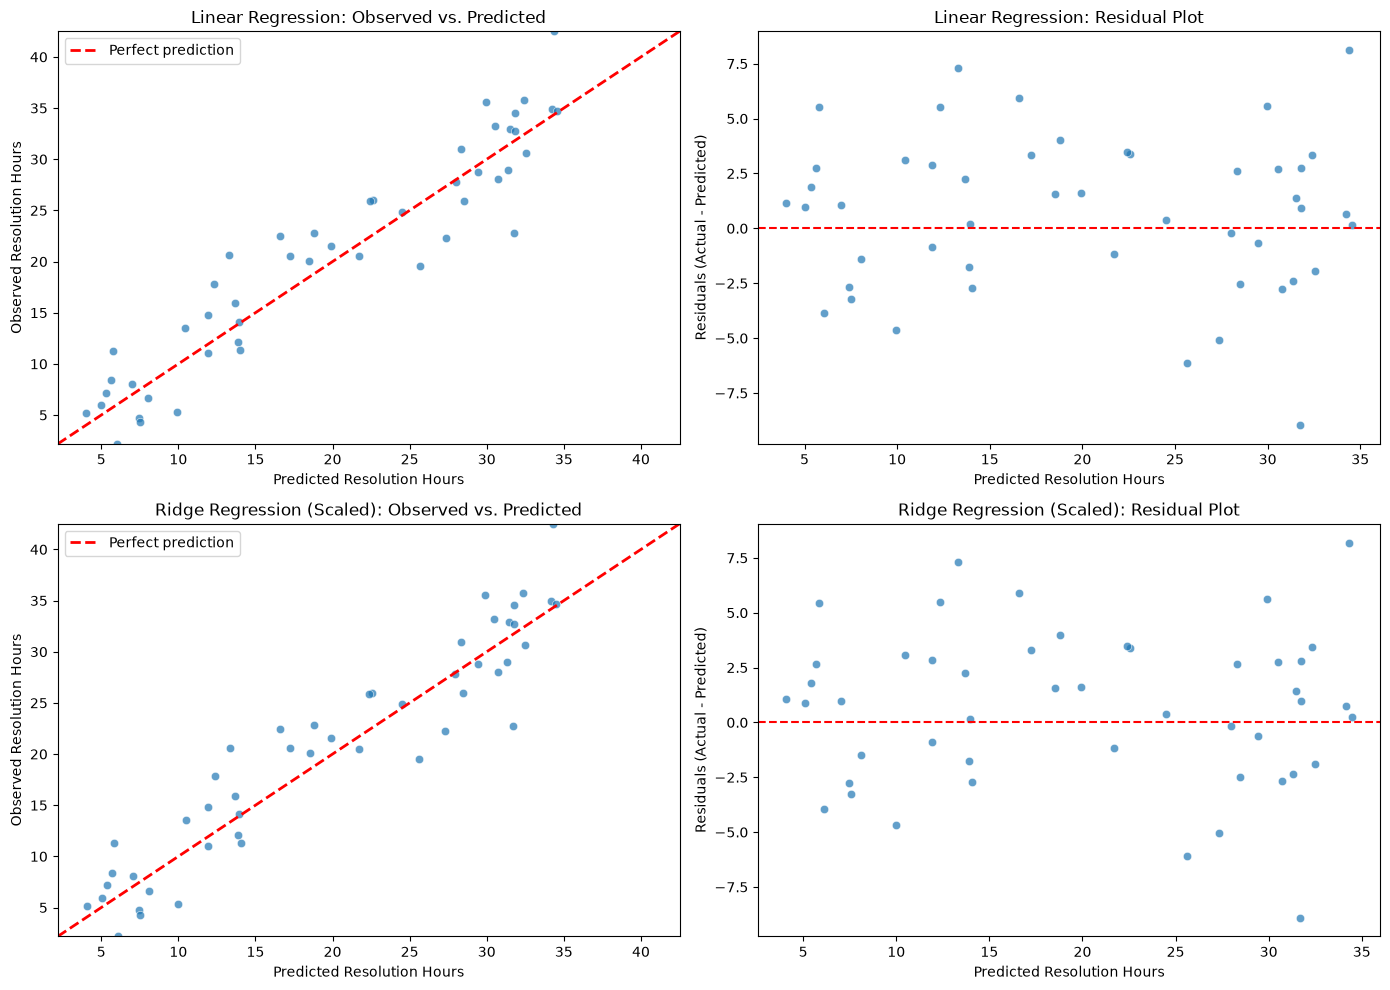

In [10]:
linear_model = models["Linear Regression"]
ridge_pipeline = regularized_models["Ridge"]

models_to_plot = {
    "Linear Regression": linear_model.predict(X_test),
    "Ridge Regression (Scaled)": ridge_pipeline.predict(X_test)
}

# Use common limits to make the plots comparable
actual_min = y_test.min()
actual_max = y_test.max()

all_predictions = np.concatenate(list(models_to_plot.values()))
pred_min = min(actual_min, all_predictions.min())
pred_max = max(actual_max, all_predictions.max())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, (name, y_pred) in enumerate(models_to_plot.items()):
    residuals = y_test - y_pred

    # Observed vs. predicted
    ax_obs = axes[idx, 0]
    sns.scatterplot(
        x=y_pred, y=y_test, ax=ax_obs, alpha=0.7
    )
    ax_obs.plot(
        [pred_min, pred_max],
        [pred_min, pred_max],
        "r--", linewidth=2, label="Perfect prediction"
    )
    ax_obs.set_xlim(pred_min, pred_max)
    ax_obs.set_ylim(pred_min, pred_max)
    ax_obs.set_title(f"{name}: Observed vs. Predicted")
    ax_obs.set_xlabel("Predicted Resolution Hours")
    ax_obs.set_ylabel("Observed Resolution Hours")
    ax_obs.legend()

    # Residual plot
    ax_res = axes[idx, 1]
    sns.scatterplot(
        x=y_pred, y=residuals, ax=ax_res, alpha=0.7
    )
    ax_res.axhline(0, color="red", linestyle="--")
    ax_res.set_title(f"{name}: Residual Plot")
    ax_res.set_xlabel("Predicted Resolution Hours")
    ax_res.set_ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()

### Observed vs. Predicted Values and Residual Analysis

I plotted the observed versus predicted resolution times and residual plots for Linear Regression and Ridge Regression.

In the observed-versus-predicted plots, most points lie reasonably close to the perfect-prediction line, indicating that both models predict resolution times relatively well. However, some points deviate from the line, showing that prediction errors remain for certain tickets.

The residual plots show positive and negative residuals distributed around the zero line. There is no obvious, consistent curved pattern or unmistakable funnel shape, although the spread of residuals varies across predicted values. A few observations have relatively large residuals and may require further investigation. These points could represent tickets that are difficult for the models to predict accurately, but additional analysis would be needed to determine whether they are influential observations.

The two models have very similar plots, suggesting that Ridge Regression provides little visible improvement over ordinary Linear Regression for this dataset.

### Model Recommendation

I would choose **Linear Regression** for this dataset because it provides a good balance of predictive performance and simplicity. It achieved a test MAE of 2.9060 hours, RMSE of 3.5723 hours, and \(R^2\) of 0.8840, substantially outperforming the Dummy Regressor baseline (MAE of 9.1140 hours and RMSE of 10.5977 hours). Although Ridge Regression performed marginally better, its improvement was negligible. Polynomial Regression of degrees 2 and 3 also performed worse than Linear Regression on the test set. Cross-validation slightly favored degree 2 among the polynomial models, but the improvement was small. 

Overall I selected Linear Regression because it achieves good predictive accuracy without unnecessary complexity.

# Analysis Questions

## 10. Why is the mean baseline useful even though it ignores all features?

The mean baseline provides a simple reference point by predicting the average resolution time for every ticket. It helps determine whether more complex models actually learn useful patterns from the input features. In this case, Linear Regression significantly outperformed the baseline, demonstrating that `complexity_score` and `team_experience_years` provide useful predictive information.

## 11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?

**Ridge Regression** achieved the lowest MAE (2.9052 hours) and the lowest RMSE (3.5705 hours), although its advantage over Linear Regression was negligible.

MAE measures the average absolute prediction error, while RMSE penalizes larger errors more heavily because it squares the residuals before averaging them. Therefore, the two metrics can favor different models when their prediction errors have different distributions.

## 12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?

Among the polynomial models, degree 2 performed better in cross-validation, with a mean RMSE of 3.8325 hours compared with 3.8766 hours for degree 3. However, on the test set, degree 2 performed worse than Linear Regression: its RMSE was 3.7409 hours compared with 3.5723 hours.

This suggests that polynomial features did not improve test performance. The gap between training and validation errors would provide stronger evidence of overfitting.

## 13. How did regularization affect performance and coefficient magnitudes?

Ridge and Lasso regularization penalize large coefficients, helping reduce model complexity and potentially limit overfitting. Ridge shrinks coefficients toward zero, while Lasso can shrink some coefficients completely to zero.

## 14. Why is scaling included in the Ridge/Lasso pipeline?

Scaling puts features on comparable scales, which is important because Ridge and Lasso penalize coefficient magnitudes. Without scaling, features with different numerical ranges could be penalized unfairly.

Including StandardScaler in the pipeline also ensures that scaling is learned from each training fold, helping prevent data leakage during cross-validation.

## 15. Identify one potential leakage issue in the dataset and explain how you handled it.

The reopened feature could cause data leakage because it may only be known after a ticket has been resolved and subsequently reopened. Since the goal is to predict resolution time when a new ticket arrives, this information would not be available at prediction time.

I excluded reopened and used only complexity_score and team_experience_years, assuming both are available when the prediction is made.

## 16. Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams? Explain.

A random split may not be appropriate in these situations because related tickets could appear in both the training and test sets, producing overly optimistic performance estimates.

If tickets span several years, I would use a time-based split, training on earlier tickets and testing on later ones. If repeated customers or teams create dependencies, I would consider a group-based split to keep each customer or team entirely within one partition, depending on how the model will be used.

## 17. What additional tests would you perform before deploying this model?

Before deployment, I would:
- Evaluate the model on a separate dataset of future tickets.
- Use cross-validation to assess how consistently it performs.
- Inspect residual plots and investigate large errors and influential observations.
- Test performance across ticket categories, complexity levels, and teams.
- Compare predictions with actual resolution times and check whether errors are acceptable for the intended use.
- Monitor performance over time to detect changes in ticket patterns or team workloads.